# Download e preparacao do UTKFace

Este notebook prepara um subconjunto do UTKFace para o codigo de difusao deste projeto.

Filtro usado:

- mulheres: `gender == 1` no padrao do UTKFace
- idade entre `20` e `40`, inclusive
- imagens RGB salvas em `128x128`

A pasta final fica pronta para ser usada diretamente pelo `ImageFolderDataset` em `dataset.py`.

In [1]:
from pathlib import Path
import shutil
import subprocess
import zipfile

from PIL import Image, ImageOps, UnidentifiedImageError
from tqdm import tqdm
import matplotlib.pyplot as plt

## Configuracoes

Se voce ja tiver baixado o UTKFace manualmente, coloque o `.zip` em `ARCHIVE_PATH` ou extraia as imagens em `RAW_DIR`.

In [2]:
MIN_AGE = 20
MAX_AGE = 40
TARGET_GENDER = 1  # UTKFace: 0 = masculino, 1 = feminino
IMG_SIZE = 128

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "data":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_PARENT_DIR = DATA_DIR / "raw"
RAW_DIR = RAW_PARENT_DIR / "UTKFace"
ARCHIVE_PATH = RAW_PARENT_DIR / "UTKFace.zip"
PROCESSED_DIR = DATA_DIR / f"utkface_female_{MIN_AGE}_{MAX_AGE}_{IMG_SIZE}"

KAGGLE_DATASET = "jangedoo/utkface-new"
USE_KAGGLE_DOWNLOAD = False

RAW_PARENT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print(f"RAW_DIR: {RAW_DIR}")
print(f"ARCHIVE_PATH: {ARCHIVE_PATH}")
print(f"PROCESSED_DIR: {PROCESSED_DIR}")

RAW_DIR: data/raw/UTKFace
ARCHIVE_PATH: data/raw/UTKFace.zip
PROCESSED_DIR: data/utkface_female_20_40_128


## Download opcional via Kaggle

Para usar esta celula, configure antes sua credencial do Kaggle. Normalmente isso significa ter um arquivo `~/.kaggle/kaggle.json`.

Se preferir baixar manualmente, deixe `USE_KAGGLE_DOWNLOAD = False` e coloque o arquivo baixado em `./data/raw/UTKFace.zip`, ou extraia as imagens para `./data/raw/UTKFace`.

In [3]:
if USE_KAGGLE_DOWNLOAD:
    if shutil.which("kaggle") is None:
        raise RuntimeError(
            "Kaggle CLI nao encontrado. Instale com `pip install kaggle` "
            "ou baixe o dataset manualmente."
        )

    subprocess.run(
        [
            "kaggle",
            "datasets",
            "download",
            "-d",
            KAGGLE_DATASET,
            "-p",
            str(RAW_PARENT_DIR),
        ],
        check=True,
    )

    downloaded_files = sorted(RAW_PARENT_DIR.glob("*.zip"), key=lambda p: p.stat().st_mtime)
    if downloaded_files and not ARCHIVE_PATH.exists():
        downloaded_files[-1].rename(ARCHIVE_PATH)

    print("Download via Kaggle finalizado.")
else:
    print("Download via Kaggle ignorado. Usando arquivo/pasta local, se existir.")

Download via Kaggle ignorado. Usando arquivo/pasta local, se existir.


## Extracao

Esta celula extrai `ARCHIVE_PATH` se ele existir. Se as imagens ja estiverem extraidas em `RAW_DIR`, nada precisa ser baixado.

In [4]:
if ARCHIVE_PATH.exists():
    print(f"Extraindo {ARCHIVE_PATH} para {RAW_PARENT_DIR}...")
    with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_ref:
        zip_ref.extractall(RAW_PARENT_DIR)
    print("Extracao finalizada.")
else:
    print(f"Arquivo nao encontrado: {ARCHIVE_PATH}")
    print("Se o dataset ja estiver extraido, isto nao e um problema.")

Arquivo nao encontrado: data/raw/UTKFace.zip
Se o dataset ja estiver extraido, isto nao e um problema.


## Localizacao das imagens

O Kaggle pode extrair as imagens em subpastas diferentes. A busca abaixo e recursiva dentro de `./data/raw`.

In [6]:
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png"}

image_paths = sorted(
    p for p in RAW_PARENT_DIR.rglob("*")
    if p.suffix.lower() in IMG_EXTENSIONS
)

print(f"Total de arquivos de imagem encontrados em {RAW_PARENT_DIR}: {len(image_paths)}")

if len(image_paths) == 0:
    raise FileNotFoundError(
        "Nenhuma imagem encontrada. Baixe o UTKFace via Kaggle ou coloque o dataset "
        "extraido dentro de ./data/raw."
    )

Total de arquivos de imagem encontrados em data/raw: 9599


## Parser do nome do UTKFace

O formato esperado e `age_gender_race_date.jpg`, por exemplo `25_1_2_20170116174525125.jpg`.

In [7]:
def parse_utkface_filename(path):
    parts = path.stem.split("_")
    if len(parts) < 4:
        return None

    try:
        age = int(parts[0])
        gender = int(parts[1])
        race = int(parts[2])
    except ValueError:
        return None

    return {
        "age": age,
        "gender": gender,
        "race": race,
        "path": path,
    }


records = []
invalid_files = []

for path in image_paths:
    record = parse_utkface_filename(path)
    if record is None:
        invalid_files.append(path)
    else:
        records.append(record)

print(f"Arquivos com metadados validos: {len(records)}")
print(f"Arquivos ignorados por nome invalido: {len(invalid_files)}")

Arquivos com metadados validos: 9599
Arquivos ignorados por nome invalido: 0


## Filtro: mulheres entre 20 e 40 anos

In [8]:
filtered_records = [
    record for record in records
    if MIN_AGE <= record["age"] <= MAX_AGE
    and record["gender"] == TARGET_GENDER
]

print(f"Total apos filtro: {len(filtered_records)}")

if len(filtered_records) == 0:
    raise ValueError("Filtro nao retornou imagens. Verifique o dataset e os parametros.")

Total apos filtro: 4659


## Pre-processamento

As imagens sao corrigidas por EXIF, convertidas para RGB, redimensionadas com crop central e salvas como PNG.

Se quiser refazer a pasta do zero, deixe `CLEAR_OUTPUT_DIR = True`.

In [9]:
CLEAR_OUTPUT_DIR = True

if CLEAR_OUTPUT_DIR and PROCESSED_DIR.exists():
    shutil.rmtree(PROCESSED_DIR)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

saved_count = 0
failed_files = []

for record in tqdm(filtered_records, desc="Salvando imagens processadas"):
    try:
        with Image.open(record["path"]) as img:
            img = ImageOps.exif_transpose(img)
            img = img.convert("RGB")
            img = ImageOps.fit(
                img,
                (IMG_SIZE, IMG_SIZE),
                method=Image.Resampling.LANCZOS,
                centering=(0.5, 0.5),
            )
            output_path = PROCESSED_DIR / f"{saved_count:06d}.png"
            img.save(output_path)
            saved_count += 1
    except (OSError, UnidentifiedImageError) as exc:
        failed_files.append((record["path"], str(exc)))

print("Pre-processamento finalizado.")
print(f"Imagens salvas: {saved_count}")
print(f"Falhas ao abrir/salvar: {len(failed_files)}")
print(f"Pasta final: {PROCESSED_DIR}")

Salvando imagens processadas: 100%|██████████| 4659/4659 [00:21<00:00, 217.81it/s]

Pre-processamento finalizado.
Imagens salvas: 4659
Falhas ao abrir/salvar: 0
Pasta final: data/utkface_female_20_40_128


## Visualizacao rapida

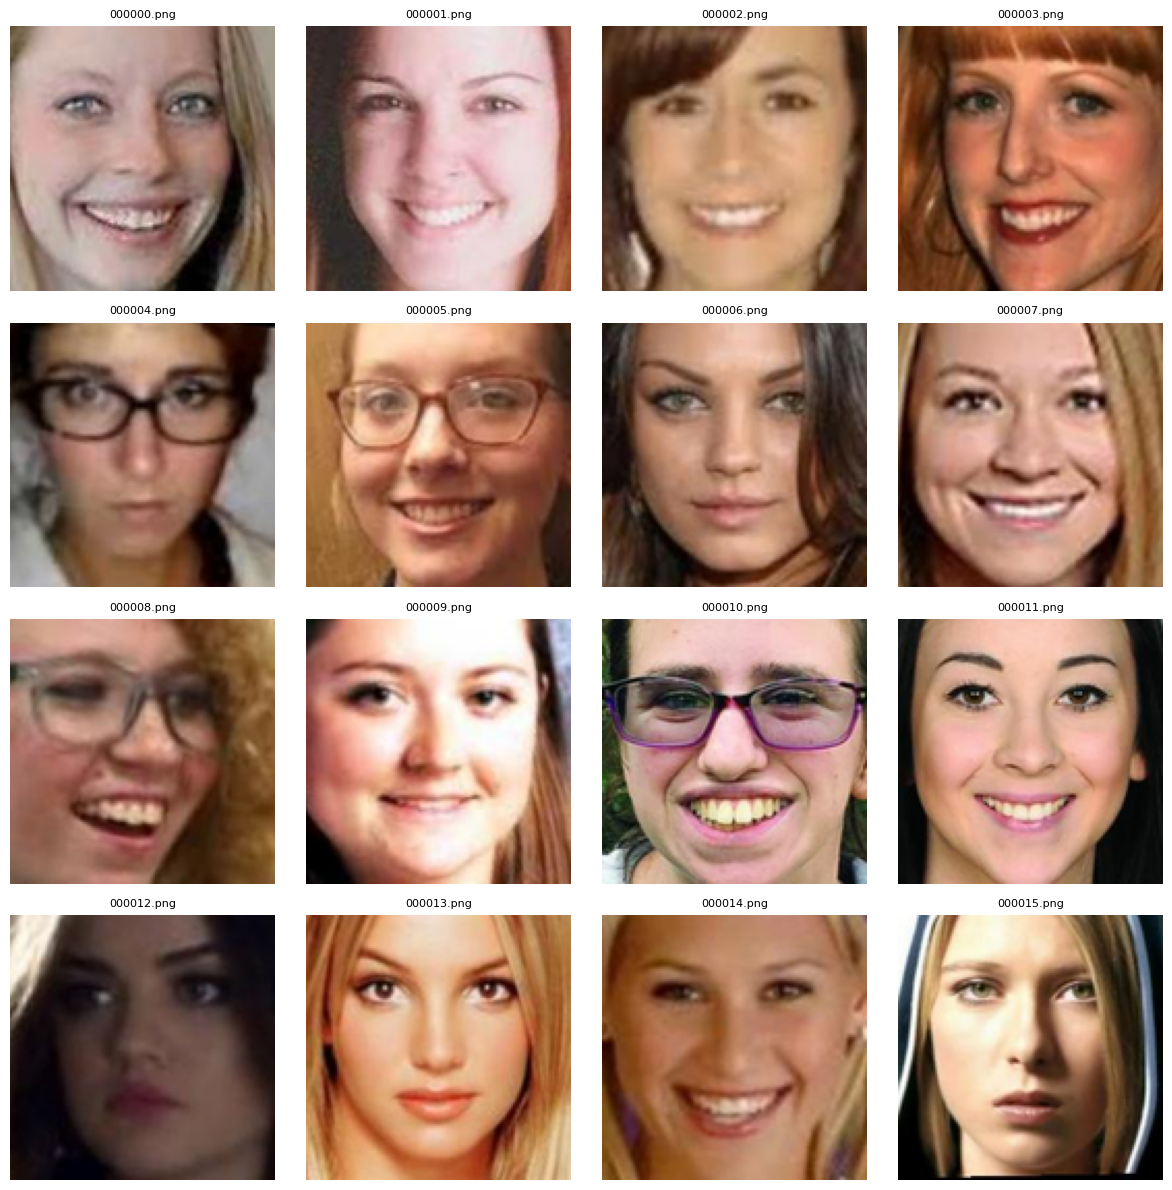

In [10]:
sample_paths = sorted(PROCESSED_DIR.glob("*.png"))[:16]

if len(sample_paths) == 0:
    print("Nenhuma imagem processada para visualizar.")
else:
    cols = 4
    rows = (len(sample_paths) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, path in zip(axes, sample_paths):
        ax.imshow(Image.open(path))
        ax.set_title(path.name, fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## Configuracao sugerida

Use estes valores no `config.yaml` para treinar o modelo de difusao neste subconjunto.

In [11]:
print("Trecho sugerido para config.yaml:")
print()
print(f'data_dir: "{PROCESSED_DIR.as_posix()}"')
print('output_dir: "./checkpoints/utkface_female_20_40_128"')
print()
print(f'image_size: {IMG_SIZE}')
print('batch_size: 32')
print('epochs: 50')
print()
print('checkpoint: "./checkpoints/utkface_female_20_40_128/diffusion_final.pt"')
print('sample_output_dir: "./samples/utkface_female_20_40_128"')

Trecho sugerido para config.yaml:

data_dir: "data/utkface_female_20_40_128"
output_dir: "./checkpoints/utkface_female_20_40_128"

image_size: 128
batch_size: 32
epochs: 50

checkpoint: "./checkpoints/utkface_female_20_40_128/diffusion_final.pt"
sample_output_dir: "./samples/utkface_female_20_40_128"
